# EDA and label audit

Explore sanitized review length, common automotive slang, and canonical label balance. The checked-in sample is only a smoke-test fixture; use an approved, de-identified corpus for meaningful analysis.

Imports and project paths

In [7]:
from pathlib import Path
import zipfile
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)

ZIP_PATH = DATA_DIR / "nhtsa_complaints_2020_2024.zip"

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Project root: d:\ML_Prep\automotive-ner-pipeline
Data directory: d:\ML_Prep\automotive-ner-pipeline\data


Download the dataset

In [8]:
DATA_URL = (
    "https://static.nhtsa.gov/odi/ffdd/cmpl/"
    "COMPLAINTS_RECEIVED_2020-2024.zip"
)

if not ZIP_PATH.exists():
    response = requests.get(DATA_URL, stream=True, timeout=60)
    response.raise_for_status()

    with open(ZIP_PATH, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)

print(f"Downloaded: {ZIP_PATH}")
print(f"Size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

Downloaded: d:\ML_Prep\automotive-ner-pipeline\data\nhtsa_complaints_2020_2024.zip
Size: 72.36 MB


Inspect the archive

In [9]:
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for info in archive.infolist():
        print(
            info.filename,
            f"{info.file_size / (1024**2):.2f} MB"
        )

COMPLAINTS_RECEIVED_2020-2024.txt 311.56 MB


Define the schema

In [10]:
columns = [
    "CMPLID", "ODINO", "MFR_NAME", "MAKETXT", "MODELTXT",
    "YEARTXT", "CRASH", "FAILDATE", "FIRE", "INJURED",
    "DEATHS", "COMPDESC", "CITY", "STATE", "VIN",
    "DATEA", "LDATE", "MILES", "OCCURENCES", "CDESCR",
    "CMPL_TYPE", "POLICE_RPT_YN", "PURCH_DT",
    "ORIG_OWNER_YN", "ANTI_BRAKES_YN", "CRUISE_CONT_YN",
    "NUM_CYLS", "DRIVE_TRAIN", "FUEL_SYS", "FUEL_TYPE",
    "TRANS_TYPE", "VEH_SPEED", "DOT", "TIRE_SIZE",
    "LOC_OF_TIRE", "TIRE_FAIL_TYPE", "ORIG_EQUIP_YN",
    "MANUF_DT", "SEAT_TYPE", "RESTRAINT_TYPE",
    "DEALER_NAME", "DEALER_TEL", "DEALER_CITY",
    "DEALER_STATE", "DEALER_ZIP", "PROD_TYPE",
    "REPAIRED_YN", "MEDICAL_ATTN", "VEHICLES_TOWED_YN",
    "STATE_OF_INCIDENT", "VEHICLE_OPERATOR"
]

assert len(columns) == 51

Load into Pandas

In [11]:
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    data_files = [
        name for name in archive.namelist()
        if name.lower().endswith((".txt", ".lst"))
    ]

    assert len(data_files) == 1, data_files

    with archive.open(data_files[0]) as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=columns,
            dtype="string",
            encoding="latin-1",
            keep_default_na=False,
            on_bad_lines="warn"
        )

print("Dataset shape:", df.shape)
display(df.head(3))

Dataset shape: (418806, 51)


,CMPLID,ODINO,MFR_NAME,MAKETXT,MODELTXT,YEARTXT,CRASH,FAILDATE,FIRE,INJURED,...,DEALER_TEL,DEALER_CITY,DEALER_STATE,DEALER_ZIP,PROD_TYPE,REPAIRED_YN,MEDICAL_ATTN,VEHICLES_TOWED_YN,STATE_OF_INCIDENT,VEHICLE_OPERATOR
0,1633421,11292384,Honda (American Honda Motor Co.),HONDA,ACCORD,2018,N,20191221,N,0,...,,,,,V,,N,N,,
1,1633422,11292384,Honda (American Honda Motor Co.),HONDA,ACCORD,2018,N,20191221,N,0,...,,,,,V,,N,N,,
2,1633423,11292384,Honda (American Honda Motor Co.),HONDA,ACCORD,2018,N,20191221,N,0,...,,,,,V,,N,N,,


Dataset structure

In [12]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.info()

Rows: 418806
Columns: 51
<class 'pandas.DataFrame'>
RangeIndex: 418806 entries, 0 to 418805
Data columns (total 51 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   CMPLID             418806 non-null  string
 1   ODINO              418806 non-null  string
 2   MFR_NAME           418806 non-null  string
 3   MAKETXT            418806 non-null  string
 4   MODELTXT           418806 non-null  string
 5   YEARTXT            418806 non-null  string
 6   CRASH              418806 non-null  string
 7   FAILDATE           418806 non-null  string
 8   FIRE               418806 non-null  string
 9   INJURED            418806 non-null  string
 10  DEATHS             418806 non-null  string
 11  COMPDESC           418806 non-null  string
 12  CITY               418806 non-null  string
 13  STATE              418806 non-null  string
 14  VIN                418806 non-null  string
 15  DATEA              418806 non-null  string
 16  LDATE 

Missing and empty values

In [13]:
empty_counts = (
    df.eq("")
      .sum()
      .sort_values(ascending=False)
)

missing_summary = pd.DataFrame({
    "empty_count": empty_counts,
    "empty_percentage": (
        empty_counts / len(df) * 100
    ).round(2)
})

display(missing_summary)

,empty_count,empty_percentage
STATE_OF_INCIDENT,418806,100.0
VEHICLE_OPERATOR,418806,100.0
FUEL_SYS,418515,99.93
TIRE_SIZE,418457,99.92
MANUF_DT,418217,99.86
RESTRAINT_TYPE,418190,99.85
SEAT_TYPE,418140,99.84
TIRE_FAIL_TYPE,418136,99.84
TRANS_TYPE,417196,99.62
ORIG_EQUIP_YN,417110,99.6


Check narrative quality

In [14]:
df["narrative_length"] = (
    df["CDESCR"].fillna("").str.len()
)

df["word_count"] = (
    df["CDESCR"]
    .fillna("")
    .str.split()
    .str.len()
)

print("Empty narratives:", (df["CDESCR"].str.strip() == "").sum())
print("Median narrative length:", df["narrative_length"].median())
print("Mean narrative length:", df["narrative_length"].mean())

display(
    df[["CDESCR", "narrative_length", "word_count"]]
    .sample(min(10, len(df)), random_state=RANDOM_STATE)
)

Empty narratives: 0
Median narrative length: 499.0
Mean narrative length: 591.8812481196544


,CDESCR,narrative_length,word_count
408052,There has been a promise to rectify this issue...,160,29
334286,Vehicle was taken to the RV dealer to have ann...,684,119
5884,TL* THE CONTACT OWNS A 2008 FORD EDGE. THE VEH...,1119,196
322366,I was on my way to work. All the warning light...,769,146
94216,TL* THE CONTACT OWNS A 2009 BUICK LUCERNE. THE...,534,90
299574,When beginning to drive forward after coming t...,858,157
313546,The contact owns a 2015 Mercedes-Benz E350. Th...,597,94
157089,1. ABS SYSTEM- ANTI-LOCK BRAKING SYSTEM SENSOR...,429,60
235085,The contact owns a 2014 Kia Sorento. The conta...,509,82
85098,TL* THE CONTACT OWNS A 2012 CHEVROLET CRUZE. T...,907,145


Narrative length distribution

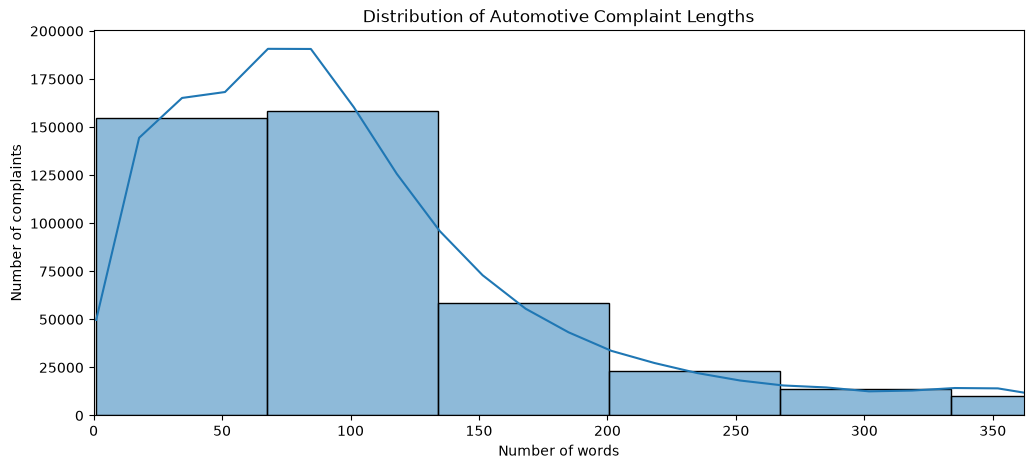

In [15]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["word_count"],
    bins=50,
    kde=True
)

plt.title("Distribution of Automotive Complaint Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of complaints")
plt.xlim(0, df["word_count"].quantile(0.99))

plt.show()

Inspect component distribution

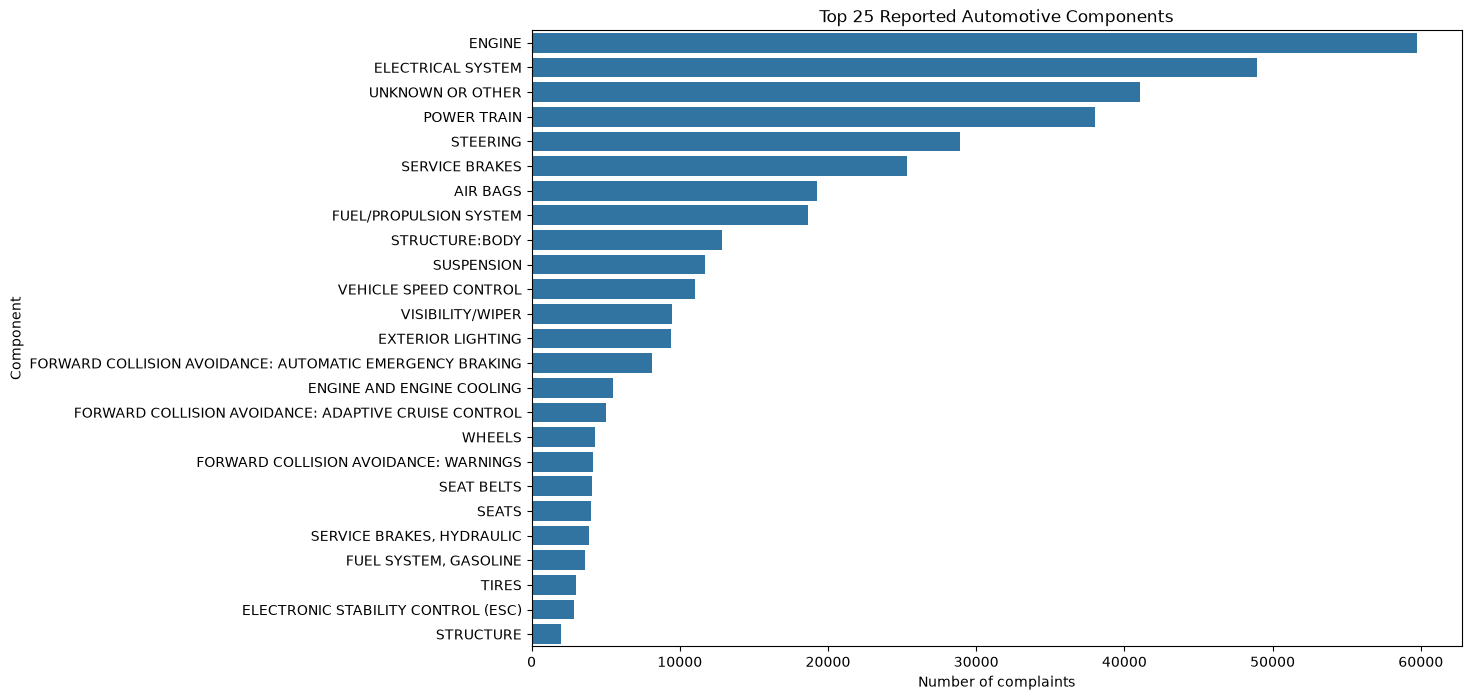

In [16]:
component_counts = (
    df["COMPDESC"]
    .str.strip()
    .replace("", pd.NA)
    .dropna()
    .value_counts()
    .head(25)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=component_counts.values,
    y=component_counts.index
)

plt.title("Top 25 Reported Automotive Components")
plt.xlabel("Number of complaints")
plt.ylabel("Component")

plt.show()

Inspect actual complaint narratives

In [17]:
sample = df[
    df["CDESCR"].str.strip().ne("")
][
    ["CMPLID", "MAKETXT", "MODELTXT", "COMPDESC", "CDESCR"]
].sample(
    min(20, len(df)),
    random_state=RANDOM_STATE
)

for _, row in sample.iterrows():
    print("=" * 100)
    print("Vehicle:", row["MAKETXT"], row["MODELTXT"])
    print("Component metadata:", row["COMPDESC"])
    print("Complaint:", row["CDESCR"])

Vehicle: TOYOTA RAV4
Component metadata: AIR BAGS
Complaint: There has been a promise to rectify this issue by Q3 2024 re: the outstanding recall for OCS sensors in passenger seat airbag. This has not been rectified yet. 
Vehicle: KEYSTONE COUGAR
Component metadata: SERVICE BRAKES
Complaint: Vehicle was taken to the RV dealer to have annual maintenance done. During inspection it was discovered that 3 of 4 brakes were covered with grease from blown bearing seals. The vehicle has less than 3,000 miles and if not addressed could have resulted in an accident due to inability to stop the trailer using the designed braking systems. The supplier of the axles and brake systems was contacted and they informed us the seals are only warranted for 1 year. Seal failures are very common on RV's and need to be addressed to provide a design which will not fail prematurely (Less than 1 trip across the country). There are no warning indicators or messages indicating brake failure.
Vehicle: FORD EDGE
Com

Basic PII protection

In [18]:
import re

def redact_pii(text):
    if not isinstance(text, str):
        return ""

    # Email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "[EMAIL]",
        text
    )

    # US-style phone numbers
    text = re.sub(
        r"\b(?:\+?1[-.\s]?)?\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}\b",
        "[PHONE]",
        text
    )

    # VIN-like 17-character identifiers
    text = re.sub(
        r"\b[A-HJ-NPR-Z0-9]{17}\b",
        "[VIN]",
        text.upper(),
        flags=re.IGNORECASE
    )

    return text

Build the working NLP dataframe

In [20]:
nlp_df = df[
    [
        "CMPLID",
        "MAKETXT",
        "MODELTXT",
        "YEARTXT",
        "COMPDESC",
        "LDATE",
        "CDESCR"
    ]
].copy()

# Keep vehicle complaints only
nlp_df = nlp_df[
    df["PROD_TYPE"].eq("V")
].copy()

# Remove empty narratives
nlp_df = nlp_df[
    nlp_df["CDESCR"].str.strip().ne("")
].copy()

# Remove duplicate complaint IDs
nlp_df = nlp_df.drop_duplicates(
    subset=["CMPLID"]
)

# Preserve original narrative separately
nlp_df["text_original"] = nlp_df["CDESCR"]

# Redact before exporting
nlp_df["text"] = (
    nlp_df["text_original"]
    .apply(redact_pii)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

nlp_df = nlp_df.reset_index(drop=True)

print("Clean dataset:", nlp_df.shape)
display(nlp_df.head())

Clean dataset: (413162, 9)


,CMPLID,MAKETXT,MODELTXT,YEARTXT,COMPDESC,LDATE,CDESCR,text_original,text
0,1633421,HONDA,ACCORD,2018,SERVICE BRAKES,20200101,"DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN...","DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN...","DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN..."
1,1633422,HONDA,ACCORD,2018,ELECTRICAL SYSTEM,20200101,"DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN...","DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN...","DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN..."
2,1633423,HONDA,ACCORD,2018,ENGINE,20200101,"DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN...","DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN...","DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN..."
3,1633424,FORD,EXPLORER,2020,ELECTRICAL SYSTEM,20200101,DEEP SLEEP MODE ACTIVATES AFTER 2 DAYS. MOST ...,DEEP SLEEP MODE ACTIVATES AFTER 2 DAYS. MOST ...,DEEP SLEEP MODE ACTIVATES AFTER 2 DAYS. MOST R...
4,1633425,CHEVROLET,VOLT,2017,SERVICE BRAKES,20200101,"WHILE DRIVING ON CITY STREETS AND HIGHWAYS, TH...","WHILE DRIVING ON CITY STREETS AND HIGHWAYS, TH...","WHILE DRIVING ON CITY STREETS AND HIGHWAYS, TH..."


Reproducible sampling

In [21]:
annotation_pool = nlp_df.sample(
    n=min(500, len(nlp_df)),
    random_state=RANDOM_STATE
).copy()

annotation_pool = annotation_pool[
    [
        "CMPLID",
        "MAKETXT",
        "MODELTXT",
        "YEARTXT",
        "COMPDESC",
        "text"
    ]
]

annotation_pool.to_csv(
    DATA_DIR / "annotation_candidates.csv",
    index=False
)

print("Annotation candidates:", len(annotation_pool))

Annotation candidates: 500
